# Exercise Sheet 6: Bayesian Optimisation  and Large Language Models

In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Created on Thursday, October 15, 11:01:00 2026

@authors: Elena Raponi, Iván Olarte-Rodríguez, and Santiago García-Mayayo

"""

'\nCreated on Thursday, October 15, 11:01:00 2026\n\n@authors: Elena Raponi, Iván Olarte-Rodríguez, and Santiago García-Mayayo\n\n'

## 1. Introduction

In this exercise sheet you will use the `LLaMEA` [https://github.com/XAI-liacs/LLaMEA] framework to generate Bayesian Optimisation-based algorithms. The main pipeline of LLaMEA is shown in the following image: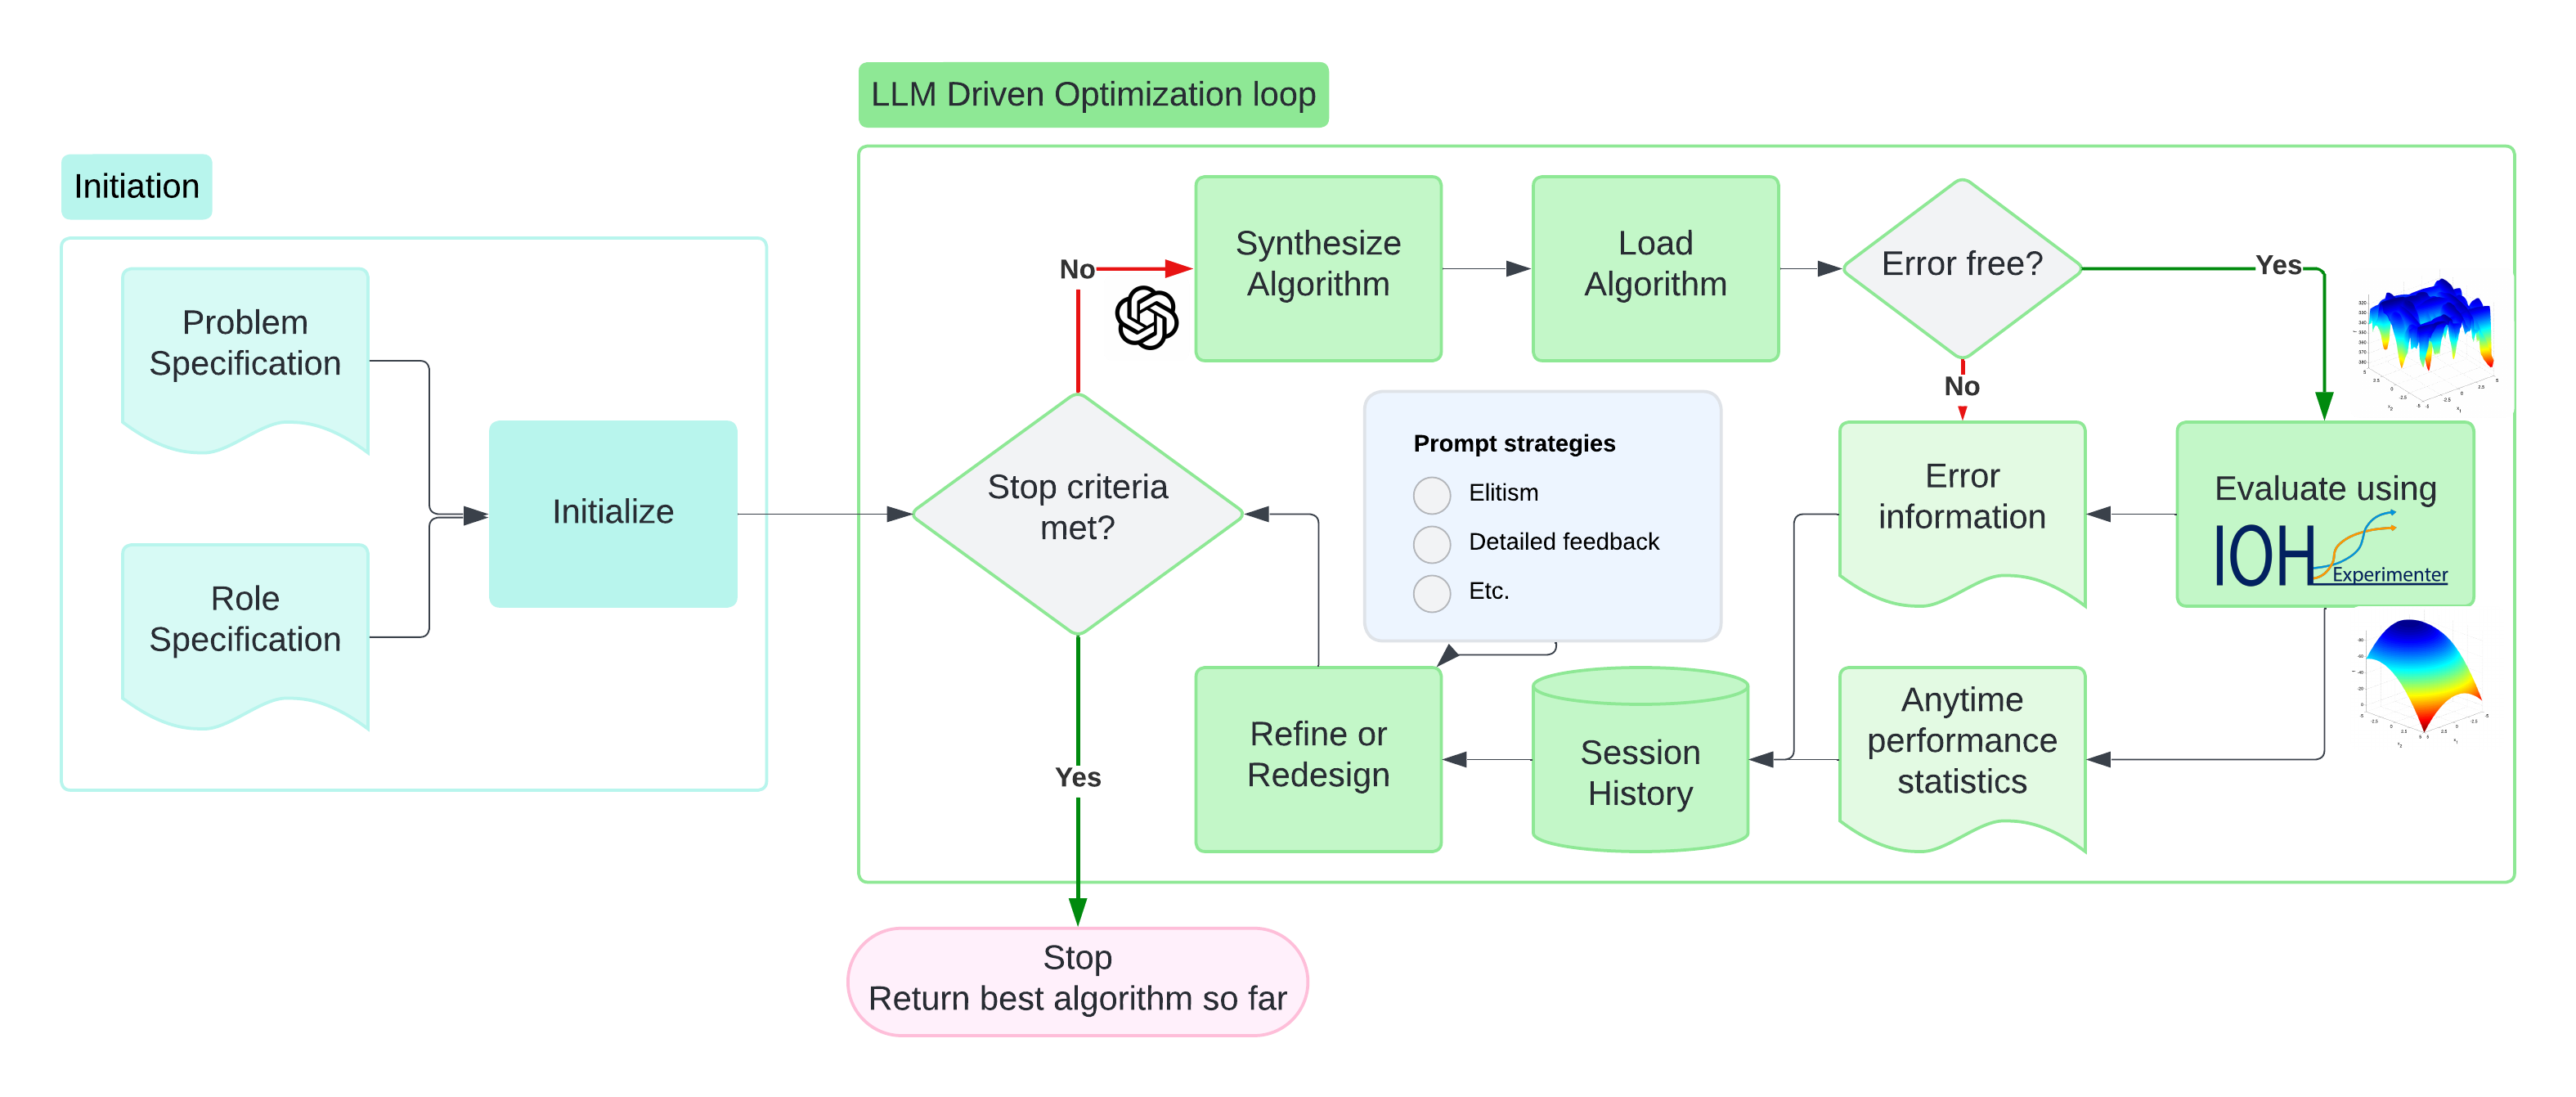.

The framework follows an iterative loop:

1) **Generate**: the LLM produces candidate algorithm code from a prompt describing the task and implementation requirements.

2) **Evaluate**: each candidate is executed on the target problems and assigned a fitness score.

3) **Select and modify**: the evolutionary strategy selects candidates, and the LLM generates variants using their code, performance feedback, and execution errors.

4) **Repeat**: the process continues until the search budget is exhausted.

For `LLaMEA`, there is a distinction between an *outer loop*, which searches over algorithms, while each candidate’s *inner loop* searches for solutions to the target optimization problem.

## 2. Review: Using IOH framework and calling the Practical Problems
For this exercise sheet, the first step for the setup is using and checking how to log results from the IOH framework. As reviewed during the first Working Groups session, you can call instances of each of the 24 BBOB Problems {https://coco-platform.org/testsuites/bbob/overview.html}. In the following code block we will in this case use a special logging device implemented from the `LLaMEA` framework to log the **AOCC** (_Area over the Convergence Curve_) metric and save it.

The AOCC is given by the following formula:
$$
\mathrm{AOCC}(\mathbf{y})=\frac{1}{B} \sum_{i=1}^{B} \left(1 - \frac{\min(\max(y_i,\mathrm{lb}),\mathrm{ub})-\mathrm{lb}}{\mathrm{ub}-\mathrm{lb}} \right)
$$

In the previous formula, $\mathbf{y}$ is the sequence of best-so-far function values reached during the optimization run, $B$ is the budget, $\mathrm{lb}$ and $\mathrm{ub}$ are the lower and upper bound of the function value range of interest. The AOCC is equivalent to the area under the so-called Empirical Cumulative Distribution Function (ECDF) curve with infinite targets between the chosen bounds.

In [3]:
!pip install ioh

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 1.7 MB/s  0:00:04m 1.7 MB/s eta 0:00:010m
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for ioh: filename=ioh-0.3.22-cp314-cp314-linux_x86_64.whl size=8498224 sha256=0b1db1b5310ee080cf237595292e80307c9de48c44f34aa7b67dc4db1c317653
  Stored in directory: /home/dario/.cache/pip/wheels/97/86/1f/25a49e8dd2492476b3388ff3524e1da979c6c8470043d7b78a
Successfully built ioh

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [4]:
# Import the necessary libraries
import llamea
import numpy as np
from ioh import LogInfo
from ioh.iohcpp.logger import AbstractLogger
from ioh import get_problem
from ioh.iohcpp.problem import RealSingleObjective
from ioh.iohcpp.logger.trigger import ALWAYS
from copy import deepcopy, copy

from typing import Union, Tuple, List, Dict, Any, Optional, Callable
import os, sys

Perhaps the first step is to define some common `Exceptions`: One may correspond to a `OverBudgetException`, which stops the optimizer running after the budget is exhausted. The other exception corresponds to a `ThresholdException` which also stops the execution of the optimizer if a problem lower bound is obtained. This latter exception is meaningful to have early stops in the execution of the algorithm to save computational resources.

In [5]:
class OverBudgetException(Exception):
    """The algorithm tried to do more evaluations than allowed."""
    pass

class ThresholdReachedException(Exception):
    """The algorithm reached the threshold of the problem."""
    pass

Then, in the following block, the definition of a `Logger` is shown. In this case, this logger computes the $\mathrm{AOCC}$ dynamically. This will help later when logging the AOCC with `IOH` without extra helpers.

In [6]:
# Define a custom logger class that inherits from AbstractLogger
# Extracted from: https://github.com/XAI-liacs/LLaMEA/blob/main/misc/utils.py
class AOCCLogger(AbstractLogger):
    """AOCC_logger class implementing the logging module for ioh."""

    def __init__(
        self,
        budget,
        lower=1e-8,
        upper=1e8,
        scale_log=False,
        stop_on_threshold=False,
        *args,
        **kwargs,
    ):
        """Initialize the logger.

        Args:
            budget (int): Evaluation budget for calculating aoc.
        """
        super().__init__(*args, **kwargs)
        self.aocc = 0.0
        self.lower = lower
        self.upper = upper
        self.budget = budget
        self.stop_on_threshold = stop_on_threshold
        self.transform = lambda x: np.log10(x) if scale_log else x

    def __call__(self, log_info: LogInfo):
        """Subcalculate the AOCC.

        Args:
            log_info (ioh.LogInfo): info about current values.
        """
        if log_info.evaluations > self.budget:
            raise OverBudgetException
        if log_info.evaluations == self.budget:
            return
        if self.stop_on_threshold and abs(log_info.raw_y_best) < self.lower:
            raise ThresholdReachedException
        y_value = np.clip(log_info.raw_y_best, self.lower, self.upper)
        self.aocc += (self.transform(y_value) - self.transform(self.lower)) / (
            self.transform(self.upper) - self.transform(self.lower)
        )

    def reset(self, func):
        super().reset()
        self.aocc = 0

Some codebases generated by the LLM might still have errors. The following function is used to compute the overall $\mathrm{AOCC}$ if the algorithm stops abruptly:

In [7]:
# This same function is found at: https://github.com/XAI-liacs/LLaMEA/blob/main/misc/utils.py
def correct_aocc(ioh_function, logger, budget):
    """Correct aocc values in case a run stopped before the budget was exhausted

    Args:
        ioh_function: The function in its final state (before resetting!)
        logger: The logger in its final state, so we can ensure the settings for aocc calculation match
        budget: The intended maximum budget

    Returns:
        float: The normalized aocc of the run, corrected for stopped runs
    """
    fraction = (
        logger.transform(
            np.clip(
                ioh_function.state.current_best_internal.y, logger.lower, logger.upper
            )
        )
        - logger.transform(logger.lower)
    ) / (logger.transform(logger.upper) - logger.transform(logger.lower))
    aocc = (
        logger.aocc
        + np.clip(budget - ioh_function.state.evaluations, 0, budget) * fraction
    ) / budget

    return 1 - aocc


Via this setup, it is possible to run experiments and store multiple evaluations of the $\mathrm{AOCC}$.

In [8]:
# This is a simple algorithm (Random Search) to have a standard call.
def random_search_alg(problem: Union[RealSingleObjective, Callable], budget:int=100, seed:int=42,
                         dimension:int=2, minimize:bool=True):
    """A simple random search algorithm for demonstration purposes.

    Args:
        problem: The optimization problem to solve.
        budget: The maximum number of evaluations allowed. Default is 100.
        seed: The random seed for reproducibility. Default is 42.
        dimension: The dimension of the search space. Default is 2.
        minimize: Whether to minimize or maximize the objective function. Default is True.

    Returns:
        best_x: The best solution found.
        best_y: The best objective value found.
        best_idx: The index of the best solution in the search history.
    """

    # Generate a random number generator with the given seed for reproducibility
    rng = np.random.default_rng(seed=seed)

    if isinstance(problem, RealSingleObjective):
        lbs = np.asarray(problem.bounds.lb)
        ubs = np.asarray(problem.bounds.ub)
        dimension_ = problem.meta_data.n_variables
    else:
        assert dimension > 0 and isinstance(dimension, int), "Dimension must be a positive integer."
        lbs = np.full(dimension, -5.0)
        ubs = np.full(dimension, 5.0)
        dimension_ = dimension

    # Initialize the placeholders for the best x and best y values
    best_x = None
    best_y = np.inf if minimize else -np.inf
    best_idx = -1

    for ii in range(budget):

        # Generate a random solution within the problem's bounds
        random_solution = rng.uniform(lbs, ubs, size=(dimension_,)).tolist()
        
        # Evaluate the random solution
        y = problem(random_solution)

        # Update the best solution if the current one is better
        if (minimize and y < best_y) or (not minimize and y > best_y):
            best_y = y
            best_idx = ii
            best_x = random_solution

    return best_x, best_y, best_idx

In [9]:
# Store the AUCs for each run
aucs = []

for dim in [5]:
    budget = 30 * dim
    l2 = AOCCLogger(budget=budget, upper=1e2, triggers=[ALWAYS], scale_log=False, stop_on_threshold=False)

    for fid in np.arange(16, 25):
        for iid in [1, 2, 3]:  
            problem = get_problem(fid=fid, instance=iid, dimension=dim)
            problem.attach_logger(l2)

            for rep in range(3):
                try:
                    algorithm = random_search_alg
                    algorithm(problem, budget=budget, seed=rep+1000, dimension=dim, minimize=True)
                except OverBudgetException:
                    print(f"Run exceeded budget for fid={fid}, iid={iid}, rep={rep}.")
                    pass

                auc = correct_aocc(problem, l2, budget)
                aucs.append(auc)
                l2.reset(problem)
                problem.reset()
    aucs = np.array(aucs)
    auc_mean = np.mean(aucs)
    auc_std = np.std(aucs)

    print(f"Dimension: {dim}, Mean AUC: {auc_mean:.4f}, Std AUC: {auc_std:.4f}")
    print(f"All AUCs: {aucs}")


Dimension: 5, Mean AUC: 0.7381, Std AUC: 0.2573
All AUCs: [0.84501081 0.83286161 0.8087163  0.7656184  0.79256502 0.77704385
 0.82962374 0.77927117 0.81335337 0.94994806 0.9231198  0.93603336
 0.94587393 0.94580352 0.9319466  0.95405539 0.9381304  0.92182873
 0.77529183 0.67473329 0.80039681 0.72642451 0.81386474 0.74653842
 0.81956211 0.71643747 0.7740484  0.90744743 0.87916533 0.9238727
 0.90721707 0.89848783 0.91297301 0.90228467 0.9290208  0.93303701
 0.00998307 0.00666667 0.29482136 0.00666667 0.28876818 0.86287139
 0.00666667 0.00666667 0.28989066 0.81552191 0.86909648 0.91187532
 0.87879009 0.90009674 0.8887061  0.73691878 0.85085666 0.80651283
 0.64019946 0.73543042 0.87173201 0.7648229  0.80045363 0.68844471
 0.64927049 0.81083834 0.7984518  0.96049392 0.96742531 0.93577969
 0.96471554 0.95631123 0.96473845 0.95271004 0.95361946 0.99089458
 0.57107768 0.53183835 0.62737553 0.45234143 0.4031714  0.35433443
 0.31984495 0.51417132 0.44058417]


Since the `Practical_Problem` suite is built upon `ioh`, the same procedure is used as before. However, notice that the suite does not contain any instances, as these problems are fixed.

In [11]:
!pip install "git+https://github.com/BayesOptApp/Practical_Problems.git"

  Cloning https://github.com/BayesOptApp/Practical_Problems.git to /tmp/pip-req-build-w_tew_mv
  Running command git clone --filter=blob:none --quiet https://github.com/BayesOptApp/Practical_Problems.git /tmp/pip-req-build-w_tew_mv
  Resolved https://github.com/BayesOptApp/Practical_Problems.git to commit a82368c1dbf9f3af851e10cf4744252408164efa
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 1.3 MB/s  0:00:07m 1.3 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 1.4 MB/s  0:00:07.3 MB/s eta 0:00:02:05
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 794.2/794.2 kB 1.6 MB/s  0:00:00? eta -:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 1.3 MB/s  0:00:011.4 MB/s eta 0:00:01:01
  Created wheel for Practical_Problems: filename=practical_problems-0.1.0-py3-none-any.whl size=68231 sha256=b62368f2c494b8b96d014961a1fcc4

In [12]:
from Practical_Problems import get_practical_problem

2026-10-19 13:47:51 INFO NumExpr defaulting to 8 threads.
2026-10-19 13:47:52 INFO Failed to extract font properties from /usr/share/fonts/noto/NotoColorEmoji.ttf: Non-scalable fonts are not supported
2026-10-19 13:47:53 INFO generated new fontManager


In [13]:
aucs = []

for dim in [6]:
    budget = 30 * dim
    l2 = AOCCLogger(budget=budget, upper=1e10, lower=1e-10, triggers=[ALWAYS], scale_log=False, stop_on_threshold=False)

    for fid in [1124, 1125, 1129]:
    #for fid in [1130]: # Activate if you want to test, however this one is slow.

        if fid==1124:
            l2.scale_log = True
            l2.lower = 1e-3
            l2.upper = 1e3
        elif fid==1125:
            l2.lower = -5.00
            l2.upper = 1e-5
        elif fid==1129:
            l2.lower = -10.0
            l2.upper = 1e-08

        elif fid==1130:
            l2.lower = -1e11
            l2.upper = 1e-08
        problem = get_practical_problem(idx=fid, dim=dim)
        problem.attach_logger(l2)

        for rep in range(3):
            try:
                algorithm = random_search_alg
                algorithm(problem, budget=budget, seed=rep+1000, dimension=dim, minimize=True)
            except OverBudgetException:
                print(f"Run exceeded budget for fid={fid}, iid={iid}, rep={rep}.")
                pass

            auc = correct_aocc(problem, l2, budget)
            aucs.append(auc)
            l2.reset(problem)
            problem.reset()
    aucs = np.array(aucs)
    auc_mean = np.mean(aucs)
    auc_std = np.std(aucs)

    print(f"Dimension: {dim}, Mean AOCC: {auc_mean:.4f}, Std AOCC: {auc_std:.4f}")
    print(f"All AOCCs: {aucs}")


Dimension: 6, Mean AOCC: 0.3108, Std AOCC: 0.4333
All AOCCs: [0.99129485 0.938183   0.83433217 0.00556673 0.00566212 0.00558145
 0.00555556 0.00555556 0.00555556]


In the previous examples, the $\mathrm{AOCC}$ was computed. In both cases there was an application of aggregation over a portfolio of functions. If there were more algorithms, there should be multiple aggregations of the $\mathrm{AOCC}$ and the practitioner may select the best performing algorithm as the one with higher mean $\mathrm{AOCC}$.

## 3. Setting up an LLM Service

`LLaMEA` already has interface to attach many different services such as `DeepSeek`, `OpenAI`, `Google-Gemini`, `Ollama` and `Anthropic`. For more information, check the repo: https://github.com/XAI-liacs/LLaMEA/blob/main/llamea/llm.py.

In the following blocks, the configuration of a free `Gemini` model is shown. To obtain an _API KEY_ for `Google` services, go to: https://aistudio.google.com/api-keys.

In [32]:
#gemini_api_key = os.environ.get("GEMINI_API_KEY")
from llamea import OpenAI_LLM

# note the variable name is misleading rn
gemini_llm_obj = OpenAI_LLM(os.environ.get("OPENAI_KEY"), "gpt-6-luna", 1.0) # temperature needs to be >= 1 for gpt-6-luna


In other cases, for free providers such as `OpenRouter` or `Groq`, it is sometimes necessary to implement a wrapper for their corresponding _APIs_. In numerous cases, however, the interfaces of these free providers is inspired from `OpenAI` ones. An implementation of a wrapper from a `Groq`. For configuring your `Groq` account and activate an _API KEY_, go to: https://console.groq.com/keys.

In [23]:
!pip install torch==2.13.0 torchvision==0.28.0 --index-url https://download.pytorch.org/whl/cu130
!pip install botorch

Looking in indexes: https://download.pytorch.org/whl/cu130

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
  Using cached ninja-1.13.2-py3-none-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.metadata (5.4 kB)
  Using cached mypy_extensions-1.1.0-py3-none-any.whl.metadata (1.1 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.0/6.0 MB 11.8 MB/s  0:00:003.1 MB/s eta 0:00:01:01
Using cached ninja-1.13.2-py3-none-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (183 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 11.1 MB/s  0:00:00 11.8 MB/s eta 0:00:01
Using cached mypy_extensions-1.1.0-py3-none-any.whl (5.0 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11/11 [botorch]━ 10/11 [botorch]pytorch]arn]

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


## 4. Generate an experimental environment for the inner loop
To run the inner loop, a function with a special signature is required. The function shall receive minimally two objects:
1. A `solution`. The `solution` corresponds to an object already managed by `LLaMEA` which corresponds to a codebase with properties sucha as the `code` and a `name`. Also to configure extra parameters, the user may specify more options via `kwargs`.
2. An `ExperimentLogger`: This is an object which logs the exchanges between `LLaMEA` and the `LLM` to generate algorithms via codebases.

In the following block, you will see an example of this environment, which already implements the same "testing environment" developed before based on computing the $\mathrm{AOCC}$.

##

In [33]:
# This imports the prepare_namespace function, which is used to create a safe execution environment for the generated code.
from llamea.utils import prepare_namespace

# This imports the Solution and ExperimentLogger classes, which are used to represent 
# the generated solution and log the evaluation process.
from llamea import Solution, ExperimentLogger

# Given that in our example to generate code, we will use torch, gpytorch, botorch, scipy, numpy, and math, we will allow these libraries in the namespace.
from torch import Tensor

def evaluate_simple(
    solution: Solution,
    explogger: Optional[ExperimentLogger] = None,
    **kwargs,
):
    """Evaluate a generated algorithm across dimensions, functions, and instances."""

    code_str = solution.code
    alg_name = solution.name

    try:
        ns, _ = prepare_namespace(
            code_str,
            allowed=[
                "torch",
                "gpytorch",
                "botorch",
                "scipy",
                "numpy",
                "math",
            ],
            logger=explogger,
        )

        # Use one namespace so generated methods can access imports
        # and helper functions defined in the generated code.
        exec(code_str, ns, ns)

        # Retrieve the generated algorithm directly from its namespace.
        algorithm_class = ns[alg_name]

        if not callable(algorithm_class):
            raise TypeError(f"{alg_name!r} is not callable.")

    except Exception as e:
        feedback = f"Error loading generated algorithm {alg_name}: {e}"
        solution.set_scores(-1.0, feedback)
        print(feedback)
        return solution

    dims = kwargs.get("dims", [2])
    multiplier = kwargs.get("multiplier", 30)
    reps = kwargs.get("reps", 3)

    aucs = []
    errors = []

    for dim in dims:
        budget = multiplier * dim

        l2 = AOCCLogger(
            budget=budget,
            upper=1e2,
            triggers=[ALWAYS],
            scale_log=True,
            stop_on_threshold=False,
        )

        for fid in [16]:
            for iid in [1]:
                problem = get_problem(
                    fid=fid,
                    instance=iid,
                    dimension=dim,
                )
                problem.attach_logger(l2)

                for rep in range(reps):
                    try:
                        algorithm = algorithm_class(
                            budget=budget,
                            random_seed=rep + 1000,
                            dim=dim,
                            minimize=True
                        )

                        algorithm(
                            problem

                        )

                    except OverBudgetException:
                        print(
                            f"Run exceeded budget for dim={dim}, "
                            f"fid={fid}, iid={iid}, rep={rep}."
                        )

                    except Exception as e:
                        message = (
                            f"Error running {alg_name} for dim={dim}, "
                            f"fid={fid}, iid={iid}, rep={rep}: {e}"
                        )
                        errors.append(message)
                        print(message)

                    try:
                        # Preserve your scoring policy: score the available
                        # trajectory even if execution stopped early.
                        auc = correct_aocc(problem, l2, budget)
                        aucs.append(float(auc))

                    finally:
                        l2.reset(problem)
                        problem.reset()

    # Aggregate only after every dimension has been evaluated.
    aucs = np.asarray(aucs, dtype=float)

    if aucs.size == 0 or not np.all(np.isfinite(aucs)):
        feedback = (
            f"Evaluation of {alg_name} produced no scores "
            "or contained non-finite AOCC values."
        )
        solution.set_scores(-1e-01, feedback)
        solution.add_metadata("evaluation_errors", errors)
        print(feedback)
        return solution

    auc_mean = float(np.mean(aucs))
    auc_std = float(np.std(aucs))

    feedback = (
        f"The algorithm {alg_name} achieved an average Area over "
        f"the Convergence Curve (AOCC; 1.0 is best) of {auc_mean:.2f}, "
        f"with standard deviation {auc_std:.2f}."
    )

    if errors:
        feedback += (
            f"\nEncountered {len(errors)} execution error(s)."
            f"\nExample error: {errors[0]}"
        )

    print(feedback)

    solution.add_metadata("aucs", aucs.tolist())
    solution.add_metadata("evaluation_errors", errors)
    solution.set_scores(auc_mean, feedback)

    return solution

## 5. Setting up the Outer Loop
LLaMEA uses a large language model (LLM) to generate and improve optimization algorithms. 

**Remember!:** Its _outer loop searches over algorithms_, while the _inner loop runs each generated algorithm on the target optimization problem_.

### Main inputs

1. **Evaluation function (`f`):** Defines how candidate algorithms are assessed. It runs each candidate on the target problem(s) and provides a fitness score and feedback, such as performance information or execution errors.

2. **Language model (`llm`):** Generates the initial algorithms and modifies existing candidates using the instructions and evaluation feedback.

3. **Prompts (`role_prompt`, `task_prompt`, `example_prompt`):** Describe the LLM's role, the algorithm-design task, and an optional example implementation. Together, they guide the structure, requirements, and permitted design choices of the generated code.

4. **Population sizes (`n_parents`, `n_offspring`):** Specify how many parent algorithms are maintained and how many new candidates are generated per generation.

5. **Selection rule (`elitism`):** Determines which candidates can survive into the next generation:
   - **`True`:** Parents and offspring compete for survival.
   - **`False`:** The next parent population is selected from offspring only.

6. **Search budget (`budget`):** Sets the number of outer-loop generations. This is separate from the number of objective evaluations available to each generated algorithm.

7. **Experiment name (`experiment_name`):** Identifies the run and organizes its logs and generated outputs.

### How mutation works

Mutation is performed by the **LLM through code modification**. The model receives a parent algorithm together with instructions and evaluation feedback, then produces a modified implementation called an **offspring**.

For a Bayesian optimization algorithm, a mutation might change the surrogate model, acquisition function, initial sampling strategy, acquisition optimizer, or numerical settings. The changes depend on the prompts and any imposed restrictions; mutation does not necessarily mean changing only a few numerical parameters.

The offspring is evaluated, and its fitness and feedback inform selection and subsequent modifications.

### Why this is an evolutionary algorithm

LLaMEA follows the main principles of evolutionary search:

1. **Population:** Candidate solutions are algorithm implementations.
2. **Variation:** LLM-based mutation produces new implementations from existing ones.
3. **Fitness evaluation:** The evaluation function measures each candidate's quality.
4. **Selection:** Candidates are chosen to form the next parent population.
5. **Iteration:** This process repeats until the outer-loop budget is exhausted.

Evolution therefore occurs at the **algorithm level**: LLaMEA evolves the code that solves the optimization problem.

With `n_parents=1`, `n_offspring=1`, and `elitism=False`, the configuration uses a **(1,1) strategy**: one parent produces one offspring, which becomes the next parent even when it performs worse. With `elitism=True`, it becomes a **(1+1) strategy**, where the better candidate survives.


The following block puts down everything altogether!

Besides also using the implementation below, there are other tunable parameters such as:

#### Additional outer-loop settings

Beyond the basic configuration, LLaMEA provides options for controlling variation, selection, evaluation, and diversity. Availability depends on the installed version.

##### Mutation and crossover

1. **`operators`:** Supplies mutation and crossover operators. Each operator defines its instructions (`prompt`), selection weight (`weight`), and required number of parents (`number_of_parents`). One parent supports mutation; multiple parents allow crossover.

2. **Mutation instructions (`prompt` within an operator):** Tell the LLM how to modify an algorithm—for example, refine numerical settings, replace an acquisition function, or redesign a major component.

3. **`operator_weight_updater`:** Controls how operator selection weights change in response to offspring performance.

4. **`adaptive_mutation`:** Enables adaptive control of mutation strength.

5. **`adaptive_prompt`:** Allows the LLM to revise the task prompt during evolution.

6. **`diff_mode`:** Requests code patches instead of complete rewritten implementations.

##### Selection and output

7. **`parent_selection`:** Chooses parents using `"random"`, `"tournament"`, or `"roulette"` selection.

8. **`tournament_size`:** Sets the tournament size.

9. **`output_format_prompt`:** Specifies the required response structure.

10. **`minimization`:** Sets whether lower fitness is better; the documented default is `False`.

##### Evaluation and search management

11. **`eval_timeout`:** Limits evaluation time.

12. **`max_workers` / `parallel_backend`:** Configure parallel evaluation.

13. **`evaluate_population`:** Makes the evaluator accept a population of candidates.

14. **`HPO`:** Enables integration with hyperparameter optimization.

15. **`log`:** Controls experiment logging.

16. **`multi_objective` / `multi_objective_keys`:** Enable multiple objectives and identify their names.

17. **`niching`:** Enables diversity management; related controls include `distance_metric`, `niche_radius`, `adaptive_niche_radius`, and `clearing_interval`.

In [36]:
from llamea import LLaMEA
import re, textwrap

# Denotes the role of the LLM in the optimization task, which is to generate Python code for Bayesian Optimization.
role_prompt = """You are an specialist in bayesian optimization who is very recognized. 
Your job description includes the generation of python code for bayesian optimization problems."""

# The task prompt specifies the requirements for the generated code, including the class name, methods, and libraries to use.
# In this case we are prompting the LLM to generate a class that implements Bayesian Optimization using BoTorch and GPyTorch, with specific methods and functionality.
# We are asking a difficult task, which is to implement GP hedges which are difficult to implement and require a good understanding of the BoTorch framework 
# and the underlying mathematics.

task_prompt = textwrap.dedent("""\
Create a Python class named Optimize_with_BO, with __init__(self, budget, dim, initial_points, random_seed) that initializes the budget and dimension, 
the initial DoE points and the random seed (for ulterior Sobol samplers from torch or for LHS from scipy),
and a __call__(self, func) method that tries to find x in [-5, 5]^2 that minimizes func(x) (this can be set randomly, 
but imagine it's a highly multimodal function like the Gallagher 101 peaks).
The function should return the tuple best_f, best_x (value best found and the location).
Implement an efficient algorithm for this Bayesian Optimization task. The code you implement must
only use BoTorch and GPyTorch libraries for the optimization; 

You may also use scipy to generate random samples for the initial DoE and then transform the variables from lists or numpy arrays into torch tensors. 
Do not use any other optimization libraries. You may append additional helper functions or classes if needed, but the main class must be named Optimize_with_BO and must have the specified methods.
You are free in the design of acquisition functions.

""")

# This is an example prompt that provides a template for the class that implements Bayesian Optimization using BoTorch and GPyTorch. 
# The user can fill in the implementation details for the methods as needed. As seen in previous sessions,
# we prompt the llm to implement the fallback for the _fit_model method to avoid the possibility of the fit_gpytorch_model function failing.

example_prompt = textwrap.dedent("""\
Here is an example of a class that implements Bayesian Optimization using BoTorch and GPyTorch:

class Optimize_with_BO:
    def __init__(self, budget, dim, initial_points, random_seed):
        self.budget = budget
        self.dim = dim
        if initial_points is None:
            self.initial_points = 5 * dim  # Default to 5 times the dimension if not provided
        else:
            self.initial_points = initial_points
        
        if random_seed is None:
            self.random_seed = 42  # Default random seed if not provided
        else:
            self.random_seed = random_seed
        
        self.initial_points = initial_points
        self.random_seed = random_seed
        self.minimize = True

    def __call__(self, func):
        # Implementation for Bayesian Optimization
    
        
    def eval_function(self, x, func):
        # Implementation for evaluating the function at a given point x
        # This is implemented as a list comprehension that evaluates the function at each point in X and returns a tensor of the results.
        # The function always returns numpy and requires numpy arrays as input, 
        # so we detach the tensor and convert it to a numpy array before passing it to the function.
         y = torch.tensor([func(x.detach().cpu().numpy()) for x in X], dtype=torch.double)
        return y


    def _initial_design(self):
        # Implementation for generating initial design points
        pass
    
    def _fit_model(self, X, y):
        # Implementation for fitting a GP model
        # This is a fallback in case the fit_gpytorch_model function fails which must implement ADAM or other optimizer from torch.optim
        pass
        """)


es = LLaMEA(
    f=evaluate_simple,
    llm=gemini_llm_obj,
    n_parents=1, # implementing a (1,1) evolutionary strategy, which is a simple and effective approach for optimization tasks.
    n_offspring=1,
    role_prompt=role_prompt,
    task_prompt=task_prompt,
    example_prompt=example_prompt,
    experiment_name="myexperiment_BO_Hedge", # This is the name of the experiment, which will be used to save the results and logs.
    elitism=False,
    minimization=False, # The outer loop is a maximization (maximize the AOCC) while the inner loop is a minimization (minimize the function value).
    budget=5  # Try 5 iterations for a quick demo
)

In [37]:
# Now run the evolutionary strategy to generate and evaluate the code for Bayesian Optimization.
best_solution = es.run()

print(f"Best found solution: {best_solution.name}, Score={best_solution.fitness:.4f}")
print(f"Generated code:\n{best_solution.code}")
print(f"Additional feedback: {best_solution.feedback}")


No archive path provided, standard initialisation.
Initializing first population
Releasing individual <llamea.solution.Solution object at 0x7f12b6f74410>
Started evolutionary loop, best so far: 0.0


/home/dario/leiden/bayopt/bayopt-venv/lib/python3.14/site-packages/botorch/optim/optimize.py:844: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/home/dario/leiden/bayopt/bayopt-venv/lib/python3.14/site-packages/botorch/optim/optimize.py:844: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)
/home/dario/leiden/bayopt/bayopt-venv/lib/python3.14/site-packages/botorch/optim/optimize.py:844: RuntimeWarning: Optimization failed on the second try, after generating a new se

Generation 2, best so far: 0.09893238620176999


/home/dario/leiden/bayopt/bayopt-venv/lib/python3.14/site-packages/joblib/parallel.py:1405: UserWarning: The backend class 'SequentialBackend' does not support timeout. You have set 'timeout=3615' in Parallel but the 'timeout' parameter will not be used.
  warnings.warn(


Generation 3, best so far: 0.09893238620176999


/home/dario/leiden/bayopt/bayopt-venv/lib/python3.14/site-packages/botorch/optim/optimize.py:844: RuntimeWarning: Optimization failed in `gen_candidates_scipy` with the following warning(s):
[OptimizationWarning('Optimization failed within `scipy.optimize.minimize` with status 2 and message ABNORMAL: .')]
Trying again with a new set of initial conditions.
  return _optimize_acqf_batch(opt_inputs=opt_inputs)


Generation 4, best so far: 0.1690747565101389


/home/dario/leiden/bayopt/bayopt-venv/lib/python3.14/site-packages/joblib/parallel.py:1405: UserWarning: The backend class 'SequentialBackend' does not support timeout. You have set 'timeout=3615' in Parallel but the 'timeout' parameter will not be used.
  warnings.warn(


Generation 5, best so far: 0.1690747565101389
Best found solution: Optimize_with_BO, Score=0.1691
Generated code:
import warnings

import gpytorch
import torch
from botorch.acquisition import ExpectedImprovement
from botorch.fit import fit_gpytorch_mll
from botorch.models import SingleTaskGP
from botorch.models.transforms import Normalize, Standardize
from botorch.optim import optimize_acqf

try:
    from botorch.acquisition import qLogExpectedImprovement
except ImportError:
    qLogExpectedImprovement = None


class Optimize_with_BO:
    """Sequential Bayesian optimization over [-5, 5]^dim."""

    def __init__(
        self,
        budget,
        dim,
        initial_points=None,
        random_seed=None,
        minimize=True,
        **kwargs,
    ):
        # Accept extra keyword arguments for compatibility with calling code.
        self.budget = int(budget)
        self.dim = int(dim)
        if self.budget < 1 or self.dim < 1:
            raise ValueError("budget and dim must